In [ ]:
import pandas as pd

df = pd.read_csv("../data/Amazon1.0/amazon-purchases.csv")


In [5]:
df.columns

Index(['Order Date', 'Purchase Price Per Unit', 'Quantity',
       'Shipping Address State', 'Title', 'ASIN/ISBN (Product Code)',
       'Category', 'Survey ResponseID'],
      dtype='str')

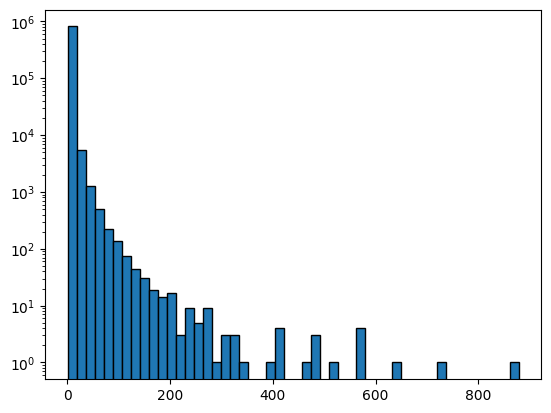

In [17]:
import matplotlib.pyplot as plt
data = sorted(df['Title'].value_counts().tolist())[:-3]
plt.hist(data, bins=50, edgecolor='black')
plt.yscale('log')
# plt.xscale('log')
plt.show()

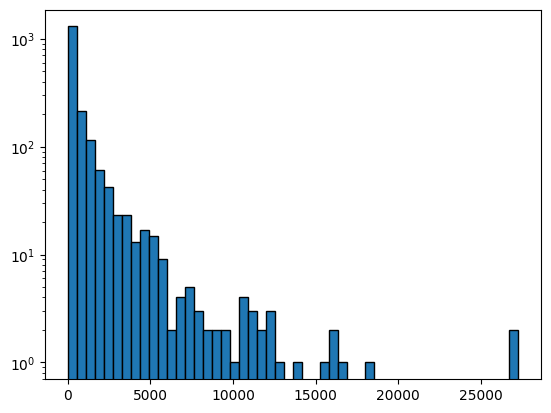

In [18]:
import matplotlib.pyplot as plt
data = sorted(df['Category'].value_counts().tolist())[:-3]
plt.hist(data, bins=50, edgecolor='black')
plt.yscale('log')
# plt.xscale('log')
plt.show()

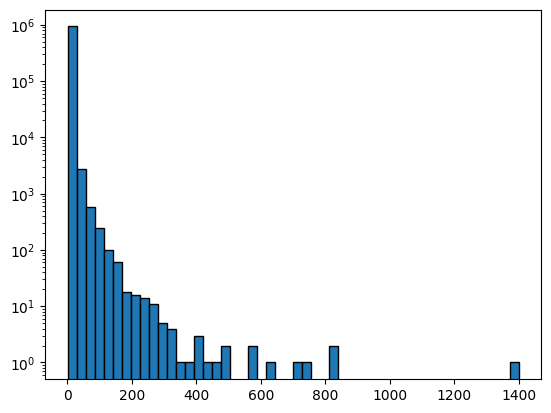

In [5]:
import matplotlib.pyplot as plt
data = sorted(df['ASIN/ISBN (Product Code)'].value_counts().tolist())[:-3]
plt.hist(data, bins=50, edgecolor='black')
plt.yscale('log')
# plt.xscale('log')
plt.show()

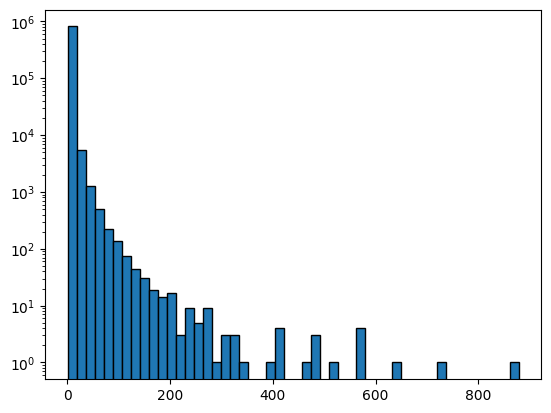

In [6]:
import matplotlib.pyplot as plt
data = sorted(df['Title'].value_counts().tolist())[:-3]
plt.hist(data, bins=50, edgecolor='black')
plt.yscale('log')
# plt.xscale('log')
plt.show()

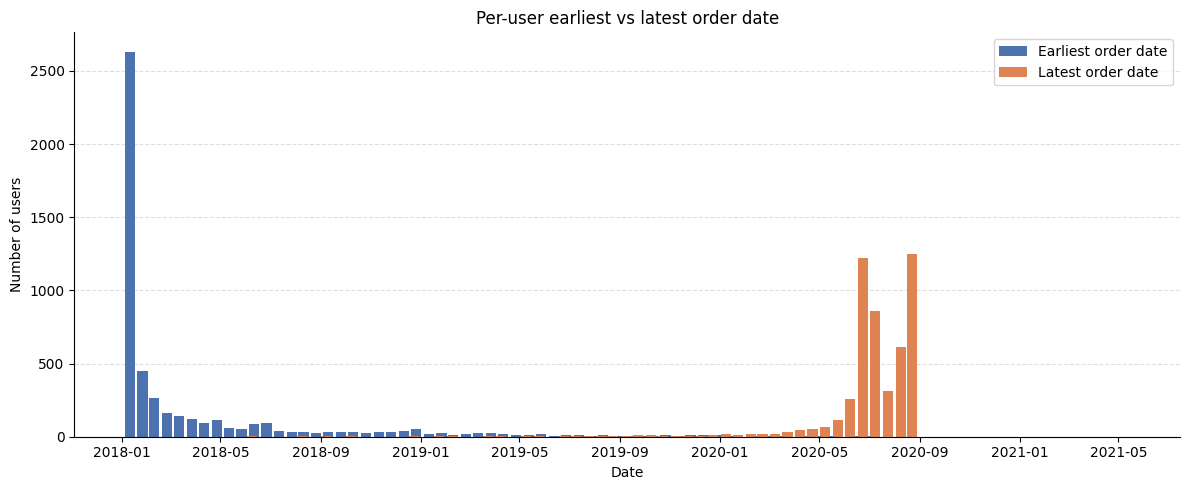

In [8]:
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df = df.dropna(subset=["Order Date", "Survey ResponseID"])

per_user = df.groupby("Survey ResponseID")["Order Date"].agg(["min", "max"])

start = per_user["min"].min().to_period("M")
end   = per_user["max"].max().to_period("M")
edges = pd.period_range(start, end, freq="M").to_timestamp()
edges = np.append(edges, edges[-1] + pd.offsets.MonthBegin(1))

earliest, _ = np.histogram(per_user["min"].values, bins=edges)
latest,   _ = np.histogram(per_user["max"].values, bins=edges)
centers = edges[:-1] + (edges[1] - edges[:-1]) / 2
width = (edges[1] - edges[0]) * 0.4

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(centers - width / 2, earliest, width=width, label="Earliest order date", color="#4C72B0")
ax.bar(centers + width / 2, latest,   width=width, label="Latest order date",   color="#DD8452")

ax.set_xlabel("Date")
ax.set_ylabel("Number of users")
ax.set_title("Per-user earliest vs latest order date")
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend()
plt.tight_layout()
plt.show()

In [9]:
d = df.sort_values("Order Date").reset_index(drop=True)
n = len(d); n_te = int(n * 0.15)
print("Test period:", d["Order Date"].iloc[n - n_te], "→", d["Order Date"].iloc[-1])

Test period: 2022-06-23 00:00:00 → 2024-08-15 00:00:00


In [16]:
len(df[df["Order Date"] > '2022-06-22']["Order Date"]) / df.shape[0]

0.1500429293079385